# 03, Decisions and calibration

Cost-sensitive thresholds (Task A), GLM inference and calibration (Task B), and an illustrative expected-loss table (Task C). Everything here runs on out-of-fold (OOF) predictions from the 80% training split. The holdout is not touched in this notebook; the final test-set run is `scripts/evaluate_holdout.py`, once, after the threshold rule is chosen.

Decision rule throughout: reject (predict bad) iff P(bad) >= threshold.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append('..')
from src.data.load import load_dataset
from src.evaluation.calibration import brier_table, calibrated, reliability_table
from src.evaluation.cost_analysis import (
    acceptance_table, cost_curve, expected_cost_at, optimal_threshold,
    sensitivity_table, theoretical_threshold,
)
from src.evaluation.cv_evaluate import oof_predict
from src.evaluation.illustrative_expected_loss import illustrative_el_table
from src.config import RANDOM_STATE
from src.evaluation.splits import get_cv_and_holdout
from src.models.glm_inference import coefficient_table, fit_glm, separation_check, vif_table
from src.models.pipelines import build_candidates

FIG_DIR = Path('../experiments/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.precision', 3)
pd.set_option('display.width', 160)

df = load_dataset()
X_train, X_test, y_train, y_test, skf = get_cv_and_holdout(df)
print(f'seed={RANDOM_STATE}, train={X_train.shape}, holdout={X_test.shape} (unused here), '
      f'train bad rate={y_train.mean():.3f}')

seed=42, train=(800, 20), holdout=(200, 20) (unused here), train bad rate=0.300


## OOF predictions

Raw models are the unchanged `build_candidates()` pipelines (LogReg and RF with `class_weight='balanced'`, XGBoost with `scale_pos_weight`). Calibrated variants wrap the same pipeline in `CalibratedClassifierCV` with an inner 5-fold CV, so the calibrator is fitted inside each outer training fold only.

In [2]:
models = build_candidates(y_train)
oof_raw = {name: oof_predict(p, X_train, y_train, skf) for name, p in models.items()}
oof_sigmoid = {name: oof_predict(calibrated(p, 'sigmoid'), X_train, y_train, skf) for name, p in models.items()}
oof_isotonic = {name: oof_predict(calibrated(p, 'isotonic'), X_train, y_train, skf) for name, p in models.items()}
variants = {'raw': oof_raw, 'sigmoid': oof_sigmoid, 'isotonic': oof_isotonic}

## Task A, cost-sensitive decisions (5:1)

Theoretical threshold assumes calibrated probabilities. The raw models are class-weighted, which shifts P(bad) upwards, so the 1/6 cutoff applied to them is shown for comparison but is not theoretically valid. The tuned threshold is the grid minimum on OOF predictions.

In [3]:
t_theory = theoretical_threshold()
print(f'theoretical threshold (5:1) = {t_theory:.4f}')

rows = []
for vname, oof in variants.items():
    for name, p in oof.items():
        t_opt, c_opt = optimal_threshold(y_train, p)
        rows.append({'model': name, 'probabilities': vname,
                     'cost_at_0.5': expected_cost_at(y_train, p, 0.5),
                     'cost_at_theoretical_1/6': expected_cost_at(y_train, p, t_theory),
                     'tuned_threshold': t_opt, 'cost_at_tuned': c_opt})
threshold_summary = pd.DataFrame(rows)
reject_all = expected_cost_at(y_train, np.ones(len(y_train)), 0.5)
print(f'reference: reject everyone = {reject_all:.3f}, approve everyone = '
      f'{expected_cost_at(y_train, np.zeros(len(y_train)), 0.5):.3f}')
threshold_summary

theoretical threshold (5:1) = 0.1667


reference: reject everyone = 0.700, approve everyone = 1.500


,model,probabilities,cost_at_0.5,cost_at_theoretical_1/6,tuned_threshold,cost_at_tuned
0,LogReg,raw,0.726,0.559,0.28,0.531
1,RandomForest,raw,0.789,0.550,0.28,0.519
2,XGBoost,raw,0.843,0.646,0.02,0.507
3,LogReg,sigmoid,1.026,0.550,0.19,0.529
4,RandomForest,sigmoid,0.964,0.520,0.17,0.517
5,XGBoost,sigmoid,0.995,0.637,0.20,0.530
6,LogReg,isotonic,1.020,0.539,0.22,0.530
7,RandomForest,isotonic,0.984,0.505,0.17,0.500
8,XGBoost,isotonic,0.991,0.522,0.16,0.514


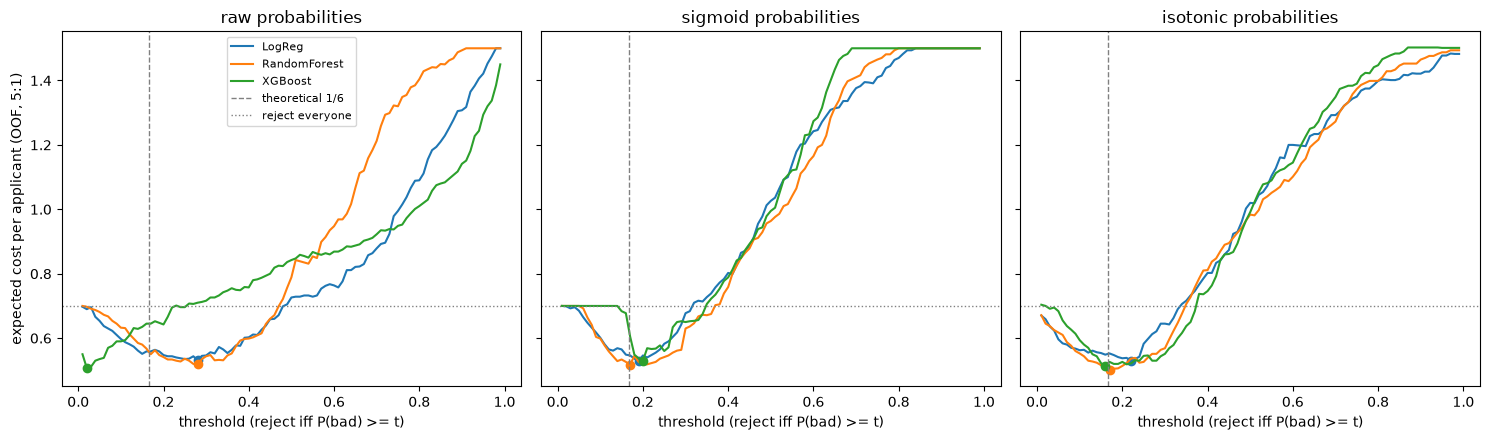

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (vname, oof) in zip(axes, variants.items()):
    for name, p in oof.items():
        curve = cost_curve(y_train, p)
        line, = ax.plot(curve['threshold'], curve['expected_cost'], label=name)
        t_opt, c_opt = optimal_threshold(y_train, p)
        ax.plot(t_opt, c_opt, 'o', color=line.get_color())
    ax.axvline(t_theory, color='grey', ls='--', lw=1, label='theoretical 1/6')
    ax.axhline(reject_all, color='grey', ls=':', lw=1, label='reject everyone')
    ax.set_title(f'{vname} probabilities')
    ax.set_xlabel('threshold (reject iff P(bad) >= t)')
axes[0].set_ylabel('expected cost per applicant (OOF, 5:1)')
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / 'cost_vs_threshold.png', dpi=150)
plt.show()

### Sensitivity to the cost ratio (FN:FP)

In [5]:
sens = pd.concat([sensitivity_table(y_train, oof).assign(probabilities=v) for v, oof in variants.items()])
sens.pivot_table(index=['probabilities', 'model'], columns='cost_ratio',
                 values=['tuned_threshold', 'cost_at_tuned', 'cost_at_theoretical'], sort=False)

tuned_threshold                   cost_at_tuned                      cost_at_theoretical                     
cost_ratio                             1:1   2:1   5:1  10:1           1:1    2:1    5:1   10:1                 1:1    2:1    5:1   10:1
probabilities model                                                                                                                     
raw           LogReg                  0.72  0.61  0.28  0.15         0.246  0.386  0.531  0.614               0.306  0.420  0.559  0.639
              RandomForest            0.56  0.43  0.28  0.17         0.239  0.364  0.519  0.588               0.269  0.389  0.550  0.639
              XGBoost                 0.80  0.20  0.02  0.02         0.245  0.376  0.507  0.614               0.268  0.385  0.646  0.909
sigmoid       LogReg                  0.44  0.28  0.19  0.12         0.251  0.385  0.529  0.615               0.261  0.394  0.550  0.641
              RandomForest            0.54  0.29  0.17  0.14         0.236  0.357  0.517  0.604               0.244  0.376  0.520  0.615
              XGBoost                 0.37  0.33  0.20  0.01         0.235  0.345  0.530  0.700               0.245  0.344  0.637  0.700
isotonic      LogReg                  0.45  0.37  0.22  0.08         0.249  0.390  0.530  0.620               0.265  0.403  0.539  0.623
              RandomForest            0.51  0.30  0.17  0.12         0.241  0.362  0.500  0.586               0.244  0.366  0.505  0.591
              XGBoost                 0.46  0.36  0.16  0.16         0.237  0.350  0.514  0.614               0.241  0.355  0.522  0.682

### Fixed acceptance-rate policy (raw probabilities; ranking only, so calibration barely matters)

In [6]:
acceptance_table(y_train, oof_raw)

,model,target_acceptance,threshold,realised_acceptance,bad_rate_among_accepted,expected_cost
0,LogReg,0.6,0.495,0.600,0.171,0.715
1,LogReg,0.7,0.624,0.700,0.188,0.787
2,LogReg,0.8,0.738,0.800,0.223,0.973
3,RandomForest,0.6,0.430,0.588,0.143,0.615
4,RandomForest,0.7,0.500,0.691,0.188,0.789
5,RandomForest,0.8,0.582,0.800,0.216,0.935
6,XGBoost,0.6,0.214,0.600,0.160,0.677
7,XGBoost,0.7,0.409,0.700,0.186,0.780
8,XGBoost,0.8,0.744,0.800,0.217,0.943


## Task B, calibration on OOF predictions

In [7]:
brier = pd.concat([brier_table(y_train, oof).assign(probabilities=v) for v, oof in variants.items()])
brier.pivot(index='model', columns='probabilities', values=['brier', 'mean_p_bad'])[
    [('brier', 'raw'), ('brier', 'sigmoid'), ('brier', 'isotonic'),
     ('mean_p_bad', 'raw'), ('mean_p_bad', 'sigmoid'), ('mean_p_bad', 'isotonic')]]

brier                  mean_p_bad                 
probabilities    raw sigmoid isotonic        raw sigmoid isotonic
model                                                            
LogReg         0.195   0.170    0.172      0.432   0.302    0.303
RandomForest   0.171   0.163    0.163      0.379   0.300    0.303
XGBoost        0.194   0.167    0.164      0.292   0.300    0.303

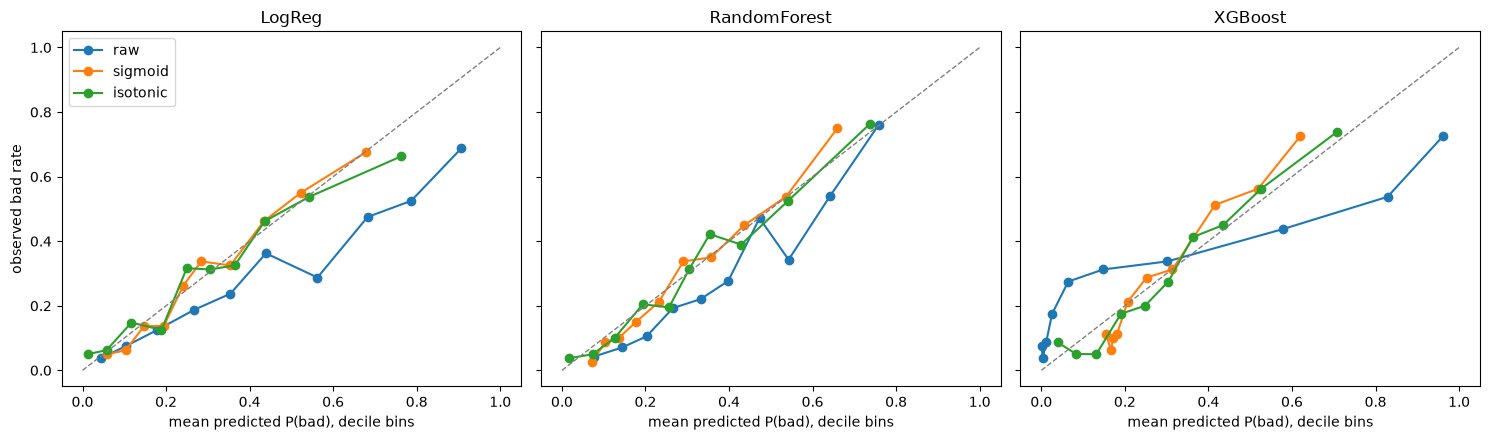

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, name in zip(axes, models):
    for vname, oof in variants.items():
        rel = reliability_table(y_train, oof[name])
        ax.plot(rel['mean_predicted'], rel['observed_bad_rate'], 'o-', label=vname)
    ax.plot([0, 1], [0, 1], color='grey', ls='--', lw=1)
    ax.set_title(name)
    ax.set_xlabel('mean predicted P(bad), decile bins')
axes[0].set_ylabel('observed bad rate')
axes[0].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'reliability_curves.png', dpi=150)
plt.show()

### Does calibration move the optimal threshold?

In [9]:
threshold_summary.pivot(index='model', columns='probabilities', values=['tuned_threshold', 'cost_at_tuned'])

tuned_threshold               cost_at_tuned               
probabilities        isotonic   raw sigmoid      isotonic    raw sigmoid
model                                                                   
LogReg                   0.22  0.28    0.19         0.530  0.531   0.529
RandomForest             0.17  0.28    0.17         0.500  0.519   0.517
XGBoost                  0.16  0.02    0.20         0.514  0.507   0.530

## Task B, logistic regression as a binomial GLM

Unweighted, unregularized, drop-first encoding, fitted on the 80% training split. A companion for inference, not the sklearn model refitted. No likelihood-ratio test: there is no trimmed feature set to compare against yet.

In [10]:
sep = separation_check(X_train, y_train)
print('levels with all-good or all-bad rows (quasi-complete separation candidates):')
print(sep.to_string(index=False) if len(sep) else '  none')

levels with all-good or all-bad rows (quasi-complete separation candidates):
  none


In [11]:
glm, Z = fit_glm(X_train, y_train)
vif = vif_table(Z)
print(f'converged: {glm.converged}, iterations: {glm.fit_history["iteration"]}')
print(f'design: {Z.shape[1]} columns + intercept, condition number of [1, Z]: '
      f'{np.linalg.cond(np.column_stack([np.ones(len(Z)), Z.values])):.1f}')
print(f'deviance {glm.deviance:.1f}, null deviance {glm.null_deviance:.1f}, AIC {glm.aic:.1f}')
print('\nVIF > 5:')
print(vif[vif['vif'] > 5].to_string(index=False) if (vif['vif'] > 5).any() else '  none')

converged: True, iterations: 6
design: 43 columns + intercept, condition number of [1, Z]: 51.3
deviance 718.7, null deviance 977.4, AIC 806.7

VIF > 5:
                         feature   vif
     nominal__credit_history_A32 8.111
     nominal__credit_history_A34 6.797
nominal__personal_status_sex_A93 5.835
nominal__personal_status_sex_A92 5.279


In [12]:
coef = coefficient_table(glm)
coef.to_csv('../experiments/glm_coefficients.csv')
coef.sort_values('p_value')

,coef,std_err,odds_ratio,or_ci_low,or_ci_high,p_value
nominal__checking_account_status_A14,-1.578,0.259,0.206,0.124,0.343,1.051e-09
const,3.517,0.828,33.696,6.653,170.669,2.144e-05
nominal__savings_account_A65,-1.149,0.302,0.317,0.175,0.573,1.421e-04
log_scale__duration_months,0.493,0.144,1.638,1.236,2.171,6.004e-04
nominal__other_installment_plans_A143,-0.875,0.268,0.417,0.247,0.704,1.074e-03
nominal__credit_history_A34,-1.596,0.490,0.203,0.078,0.530,1.138e-03
nominal__purpose_A41,-1.190,0.402,0.304,0.138,0.669,3.094e-03
nominal__property_A124,1.416,0.487,4.121,1.586,10.705,3.644e-03
scale__installment_rate,0.332,0.115,1.394,1.111,1.747,4.035e-03
nominal__housing_A153,-1.475,0.558,0.229,0.077,0.682,8.169e-03


## Task C, ILLUSTRATIVE expected loss

EL_i = PD_i x LGD x EAD_i with OOF PDs, EAD = credit_amount at origination, and LGD an **assumed** scenario constant (German Credit has no recovery data). Not a loss estimate; nothing upstream reads it. The `observed_defaults` row uses actual 0/1 outcomes as PD, i.e. realised loss under the same LGD assumption.

In [13]:
pd_sources = {'observed_defaults (0/1)': y_train.to_numpy()}
for name in models:
    pd_sources[f'{name} raw'] = oof_raw[name]
    pd_sources[f'{name} sigmoid'] = oof_sigmoid[name]
el = illustrative_el_table(pd_sources, X_train['credit_amount'])
el.to_csv('../experiments/ILLUSTRATIVE_expected_loss_assumed_LGD.csv', index=False)
el.set_index('pd_source').round(0)

,illustrative_total_EL_DM_assumed_LGD_low_0.25,illustrative_mean_EL_DM_assumed_LGD_low_0.25,illustrative_total_EL_DM_assumed_LGD_mid_0.45,illustrative_mean_EL_DM_assumed_LGD_mid_0.45,illustrative_total_EL_DM_assumed_LGD_high_0.65,illustrative_mean_EL_DM_assumed_LGD_high_0.65
pd_source,,,,,,
observed_defaults (0/1),225359.0,282.0,405647.0,507.0,585934.0,732.0
LogReg raw,307215.0,384.0,552986.0,691.0,798758.0,998.0
LogReg sigmoid,214376.0,268.0,385877.0,482.0,557378.0,697.0
RandomForest raw,270216.0,338.0,486388.0,608.0,702561.0,878.0
RandomForest sigmoid,214888.0,269.0,386799.0,483.0,558709.0,698.0
XGBoost raw,225857.0,282.0,406543.0,508.0,587228.0,734.0
XGBoost sigmoid,209048.0,261.0,376286.0,470.0,543525.0,679.0
